# Scoring a Forecast: How Far Off, on Average, in Percent?

The same code as the second half (practice part) of the video.

- **Nothing to set up** (free, no install. You just need to be signed in to a Google account)
- **How to run**: press ▶ on each cell, from the top down (or Shift + Enter). The first time, if you see “This notebook was not authored by Google”, click “Run anyway”
- **To try your own changes**: first use “File → Save a copy in Drive” so you keep your own copy

*Original code: [marcopeix/TimeSeriesForecastingInPython](https://github.com/marcopeix/TimeSeriesForecastingInPython) (Apache License 2.0), modified by Mirai Graph.*

Today's words:
- 🔰 **Error** = actual − forecast (how much it missed)
- 🔰 **MAPE** = your average miss, in % (lower is better)
- 🔰 **Naive seasonal forecast** = each quarter = the same quarter last year

## 1. Load the tools and data, then split into training and test

In the video, the data is loaded from `../data/jj.csv`, but this notebook loads the same file from a GitHub URL so it runs in Colab on its own. The contents are the same. Only `test` gets `.copy()`, because we'll add forecast columns to `test` only.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('https://raw.githubusercontent.com/marcopeix/TimeSeriesForecastingInPython/master/data/jj.csv')
train = df.iloc[:-4]
test = df.iloc[-4:].copy()

## 2. The three forecasts from Episode 2

In [2]:
test['pred_last'] = train['data'].iloc[-1]
test['pred_last_yr_mean'] = train['data'].iloc[-4:].mean()
test['pred_mean'] = train['data'].mean()

## 3. Calculate the errors

In [3]:
error = test['data'] - test['pred_last']
error

80    6.21
81    4.68
82    6.03
83    1.62
dtype: float64

## 4. A function that calculates MAPE

In [4]:
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

## 5. MAPE for the three forecasts

In [5]:
print(mape(test['data'], test['pred_last']))
print(mape(test['data'], test['pred_last_yr_mean']))
print(mape(test['data'], test['pred_mean']))

30.457277908606535
15.5963680725103
70.00752579965119


## 6. Forecast 4: same quarter last year

Without `.values`, pandas tries to match rows by their row numbers (76–79 in training and 80–83 in test). No numbers match, so all four rows become NaN (empty).

In [6]:
test['pred_last_season'] = train['data'].iloc[-4:].values
print(mape(test['data'], test['pred_last_season']))

11.561658552433654


## 7. Compare them in a bar chart

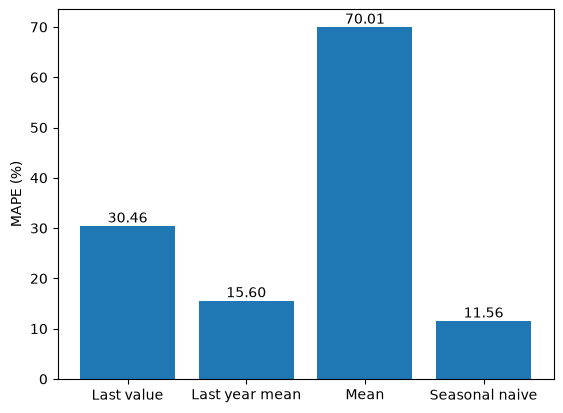

In [7]:
names = ['Last value', 'Last year mean', 'Mean', 'Seasonal naive']
scores = [mape(test['data'], test['pred_last']),
          mape(test['data'], test['pred_last_yr_mean']),
          mape(test['data'], test['pred_mean']),
          mape(test['data'], test['pred_last_season'])]
bars = plt.bar(names, scores)
plt.bar_label(bars, fmt='%.2f')
plt.ylabel('MAPE (%)');

## Try it

Note: after you edit a cell and press ▶, also run the cells below it (the table and the chart) to see the new results.

- Does a popular tool give the same score? `from sklearn.metrics import mean_absolute_percentage_error` → `mean_absolute_percentage_error(test['data'], test['pred_last_season'])` gives 0.1156… (it returns a ratio). Multiply by 100 and it's the same 11.56. Always check whether a tool gives a percent or a ratio.
- What if we add the upward slope? `growth = train['data'].iloc[-4:].sum() / train['data'].iloc[-8:-4].sum()` (the 1979 total ÷ the 1978 total = 1.152, using only the training data) → `mape(test['data'], test['pred_last_season'] * growth)` gives 2.40. With both the yearly habit and the upward slope, the forecast gets much closer. `iloc[-8:-4]` means "from the 8th from the end, up to just before the 4th from the end" = the four quarters of 1978.

In [8]:
# 1. MAPE from a popular tool (scikit-learn)
from sklearn.metrics import mean_absolute_percentage_error
mean_absolute_percentage_error(test['data'], test['pred_last_season'])

0.11561658552433654

In [9]:
# 2. Multiply by the upward slope (the 1979 total ÷ the 1978 total)
growth = train['data'].iloc[-4:].sum() / train['data'].iloc[-8:-4].sum()
print(growth)
print(mape(test['data'], test['pred_last_season'] * growth))

1.1520000000000001
2.3981786499220124


---
Code: adapted by Mirai Graph (2026) from [marcopeix/TimeSeriesForecastingInPython](https://github.com/marcopeix/TimeSeriesForecastingInPython) by the book's author, Marco Peixeiro. License: [Apache License 2.0](https://www.apache.org/licenses/LICENSE-2.0)

Data and credit: Johnson & Johnson quarterly earnings per share, 1960–1980 (Shumway & Stoffer, Time Series Analysis and Its Applications, Springer / R datasets: JohnsonJohnson; taken from data/jj.csv in the book's repository).

This notebook and the video are an independent explanation based on the book *Time Series Forecasting in Python*. They are not affiliated with the author or the publisher.